In [1]:
import tensorflow as tf
import math

from typing import Optional

from tf_ofcs.components import *
from tf_ofcs.datatypes import TensorCompatible, ElectricalSignal, OpticalSignal, Timing
from tf_ofcs.utils import to_tensor
from tf_ofcs import constants
from tf_ofcs.plot import *

import plotly.graph_objects as go

2025-03-04 20:18:20.389819: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2025-03-04 20:18:20.427290: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-03-04 20:18:20.427314: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-03-04 20:18:20.428407: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-03-04 20:18:20.434238: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2025-03-04 20:18:20.434955: I tensorflow/core/platform/cpu_feature_guard.cc:1

In [2]:
class ChromaticDispersionFrequencyResponse(Component):
    chromatic_dispersion: tf.Variable  # shape=[]; dtype=tf.float32
    central_frequency: tf.Variable  # shape=[]; dtype=tf.float32
    batch_size: tf.Variable  # shape=[]; dtype=tf.int32

    def __init__(
        self,
        chromatic_dispersion: TensorCompatible,
        central_frequency: TensorCompatible,
        batch_size: TensorCompatible = 1,
        name: Optional[str] = None
    ) -> None:
        super().__init__(name=name)

        self.chromatic_dispersion = tf.Variable(
            to_tensor(chromatic_dispersion),
            name=f"{self.name}__chromatic_dispersion"
        )
        self.central_frequency = tf.Variable(
            to_tensor(central_frequency),
            name=f"{self.name}__central_frequency"
        )
        self.batch_size = tf.Variable(
            to_tensor(batch_size),
            name=f"{self.name}__batch_size"
        )
        self.local_parameters = ["chromatic_dispersion", "central_frequency", "batch_size"]

    def implementation(
        self,
        frequencies: tf.Tensor,
        /,
        chromatic_dispersion: tf.Tensor,
        central_frequency: tf.Tensor,
        batch_size: tf.Tensor
    ) -> tf.Tensor:
        wavelength = constants.c / central_frequency
        D = chromatic_dispersion * 1e-6
        beta_2 = wavelength ** 2 / (-2.0 * constants.pi * constants.c) * D

        return tf.expand_dims(
            tf.math.exp(
                tf.complex(
                    0.0,
                    beta_2 * 0.5 * 1e3 * (2 * constants.pi * frequencies) ** 2
                )
            ),
            0
        )

In [3]:
cdfr = ChromaticDispersionFrequencyResponse(chromatic_dispersion=17.0 * 3, central_frequency=193.414e12)
gpg = GaussianPulseGenerator(fwhm_duration=[1e-11], power=[1e-3], batch_size=1)
timing = Timing(sample_count=50, sampling_rate=600e9)
input_signal = gpg(timing)
dispersion_filter = FFTFilter(cdfr)
signal_with_dispersion = dispersion_filter(input_signal)

photodiode = Photodiode()
received_signal = photodiode(input_signal)
received_signal_with_dispersion = photodiode(signal_with_dispersion)
received_signal_with_dispersion = ElectricalGain(gain=[0.5])(received_signal_with_dispersion)

In [135]:
optimizer = tf.optimizers.Adam(learning_rate=1.0)
n_taps = 5
fir_filter = Composition([
    FIRFilter(taps=tf.random.normal((1, n_taps,), mean=1.0, stddev=1.0, dtype=tf.float32)),
    SliceSignal(start=(n_taps - 1) // 2, end=-(n_taps - 1) // 2)
])

def compute_loss() -> tf.Tensor:
    return tf.math.reduce_mean(tf.square(fir_filter(received_signal_with_dispersion).samples - received_signal.samples))

@tf.function
def train(steps: tf.Tensor):
    for step in tf.range(1, steps + 1):
        optimizer.minimize(compute_loss, var_list=[fir_filter.components[0].taps])
        if step % 50 == 0:
            tf.print(tf.strings.format("Step {}, Loss: {}", (step, compute_loss())))

In [169]:
train(100)

Step 50, Loss: 1.3645475e-10
Step 100, Loss: 1.33996925e-10


In [170]:
processed_signal = fir_filter(received_signal_with_dispersion)

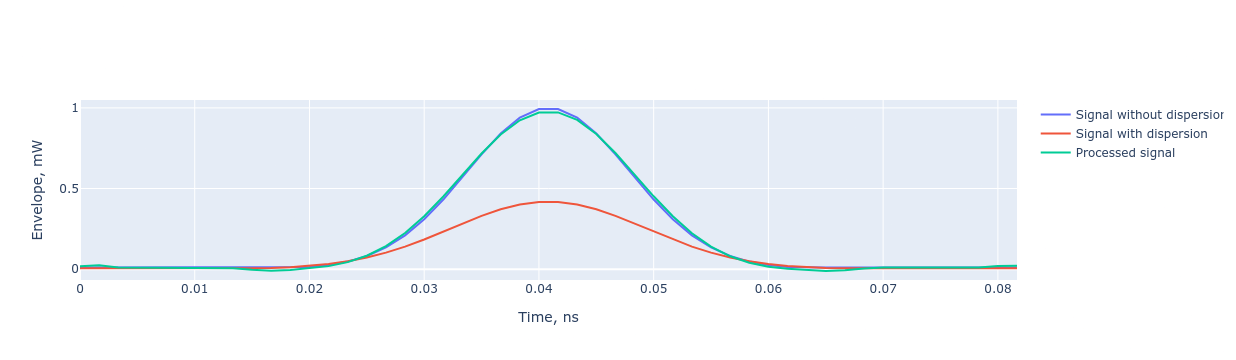

In [171]:
figure = plot_envelope(received_signal, label="Signal without dispersion", envelope_units=(1e3, "mW"))
plot_envelope(received_signal_with_dispersion, figure, label="Signal with dispersion", envelope_units=(1e3, "mW"))
plot_envelope(processed_signal, figure, label="Processed signal", envelope_units=(1e3, "mW"))